# Nondeterministic Actions: Solving Tic-Tac-Toe with AND-OR-Tree Search

## Introduction 
 
Multiplayer games can be implemented as:
1. __Nondeterministic actions:__ The opponent is seen as part of an environment with nondeterministic actions. Non-determinism is the result of the unknown opponent's moves. 
2. Optimal Decisions: Minimax search (search complete game tree) and alpha-beta pruning.
3. Heuristic Alpha-Beta Tree Search: Cut off tree search and use heuristic to estimate state value. 
4. Monte Carlo Tree search: Simulate playouts to estimate state value. 

Here we will implement search for Tic-Tac-Toe (see [rules](https://en.wikipedia.org/wiki/Tic-tac-toe)).

We will implement
* __AND-OR-Tree search.__

Each action consists of the move by the player (OR levels in the tree) and all possible (i.e., nondeterministic) responses by the opponents (AND levels). The action therefore results in a set of possible states.

We will search for a __conditional plan__ using AND-OR-Tree search. 

The code for the basic functions used for search are implemented in [tictactoe.py](tictactoe.py).

In [1]:
# download if missing
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

download("tictactoe.py", ".")

In [2]:
from tictactoe import empty_board, actions, result, terminal, utility, other, show_board
from tictactoe import random_player, play 

# --- bổ sung: thư viện và seed để kết quả tái lập được ---
import time
import numpy as np
np.random.seed(2024)

## Solving Tic-Tac-Toe using AND-OR-Tree Search

The opponent can be modeled as part of the environment. The opponent's action as a response to the agent's 
action makes the environment appear non-deterministic (see AIMA page 125 or the slides). The ADS-OR-Tree algorithm uses the following functions:

* `is_goal(state)`: determine if the current board/state has a winner.
* `is_cycle(path)`: determine if we are in a loop (the tic-tac-toe problem has no loops so I do not implement it).
* `results(state, action)`: returns all states following state + action.


### Cycles

The path is typically used for loop checking. We ignore it here since tic-tac-toe does not have cycles.

### Goals

Reaching the goal means that the agent has successfully finished the task. 

For games, `terminal(s)` checks if `s` is a terminal state, but a terminal state can also indicate that 
the player lost (which indicates a failure). This can determined by the 
`utility(s)` function. Tic-tac-toe also has draws and we need to decide if a draw is considered successfully reaching
the goal or a failure.

### Non-deterministic Results

Since the opponent and her moves are part of the environment, `results()` returns for a state $\times$ action combination a set of new states that reflects all possible responses by the opponent.

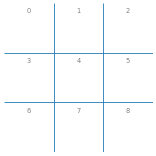


Set of possible state for placing an x at position 4 of an empty board and the opponent's move:


[['o', ' ', ' ', ' ', 'x', ' ', ' ', ' ', ' '],
 [' ', 'o', ' ', ' ', 'x', ' ', ' ', ' ', ' '],
 [' ', ' ', 'o', ' ', 'x', ' ', ' ', ' ', ' '],
 [' ', ' ', ' ', 'o', 'x', ' ', ' ', ' ', ' '],
 [' ', ' ', ' ', ' ', 'x', 'o', ' ', ' ', ' '],
 [' ', ' ', ' ', ' ', 'x', ' ', 'o', ' ', ' '],
 [' ', ' ', ' ', ' ', 'x', ' ', ' ', 'o', ' '],
 [' ', ' ', ' ', ' ', 'x', ' ', ' ', ' ', 'o']]

In [3]:
def results(state, action, player = 'x'):
    """produce the set of states after the provided action for player. 
       It is the set of boards with the action and all possible reactions by the opponent."""
    
    opponent = other(player)
    state = state.copy()
    
    # player's move
    state[action] = player
    
    # opponent reacts
    r = list()
    o_actions = actions(state)
    
    # board is full
    if len(o_actions) < 1 : return [state]
    
    for o_a in o_actions:
        s = state.copy()
        s[o_a] = opponent
        r.append(s)    
    
    return r

show_board(empty_board())

print()
print("Set of possible state for placing an x at position 4 of an empty board and the opponent's move:")
results(empty_board(), 4)

### Recursive AND-OR Search (DFS)

In [4]:
# define global variables for debugging
DEBUG = 1
COUNT = 0 # used to report the number of searched nodes

def and_or_search(state, player = 'x', draw_is_win = True):
    """start the search. Consider draw_is_win a goal state?"""
    global DEBUG, COUNT
    COUNT = 0
    
    plan = or_search(state, player, draw_is_win)
    
    if DEBUG >= 1: 
        print(f"Number of nodes searched: {COUNT}")  
    
    return plan
 

def or_search(state, player, draw_is_win):
    """Or step of the search: the player makes a move. 
    We try all possible action and return a conditional 
    plan for the first action that only has goal states as leaf nodes. 
    If none can be found, then failure (None) is returned.
    
    Note: path is not used in this implementation since tic-tac-toe does not 
    need cycle checking.
    """
    global DEBUG, COUNT
    COUNT += 1
    
    # goal check
    u = utility(state, player)
    if u == -1 or (not draw_is_win and u == 0): return None # failure
     
    # cycles check: tic-tac-toe has no cycles

    # check all possible actions
    for action in actions(state):
        plan = and_search(results(state, action, player), player, draw_is_win)
        if plan is not None: 
            return [action, plan]
    
    # failure
    return None


def and_search(states, player, draw_is_win):
    """And step of the search: Represents all opponent's possible moves. 
    Follow all possible states (call the or step). 
    Return a conditional plan only if all paths lead to a goal state."""
    global DEBUG, COUNT
    COUNT += 1
    
    # return plans only if no state fails
    plans = []
    for s in states:
        # goal check
        u = utility(s, player)
        if u == 1: return "win"  # success
        if draw_is_win and u == 0: return "draw"

        plan = or_search(s, player, draw_is_win)
        
        if plan is None: 
            return None    # found a state that fails so we abandon this subtree!
        plans.append(['if', s, 'then', plan])
        
    return plans

And-or search looks for a subtree (i.e., an action) that guarantees a win and returns a conditional plan for this subtree. If no such subtree exists, no plan is returned. The algorithm only searches a fraction of the game tree since it abandons the current subtree when it finds the first leaf node that is not a win (see `and_search` function).

## Công cụ hỗ trợ đọc kế hoạch điều kiện (phần bổ sung)

Các hàm dưới đây **không thay đổi thuật toán**, chỉ giúp (1) thống kê kế hoạch điều kiện mà `and_or_search` trả về và (2) in kế hoạch ra dạng dễ đọc *"nếu O đánh ô … thì X đánh ô …"*.

In [5]:
def plan_stats(plan):
    """Thống kê một kế hoạch điều kiện: số lá 'win', số lá 'draw' và độ sâu (số nước đi của X)."""
    action, sub = plan
    if isinstance(sub, str):            # lá: 'win' hoặc 'draw'
        return {"win": int(sub == "win"), "draw": int(sub == "draw"), "depth": 1}
    w = d = dep = 0
    for _, s, _, p in sub:               # mỗi phần tử: ['if', trạng_thái_sau_phản_ứng_của_O, 'then', kế_hoạch_con]
        r = plan_stats(p)
        w += r["win"]; d += r["draw"]; dep = max(dep, r["depth"])
    return {"win": w, "draw": d, "depth": dep + 1}


def print_plan(plan, state, player='x', max_depth=3, indent=0):
    """In kế hoạch điều kiện dạng cây thụt lề (chỉ in max_depth tầng đầu)."""
    a, sub = plan
    pad = "    " * indent
    b = result(state, player, a)
    if isinstance(sub, str):
        print(f"{pad}X đánh ô {a}  =>  {sub.upper()}")
        return
    print(f"{pad}X đánh ô {a}")
    if max_depth <= 1:
        print(f"{pad}    ... (còn {len(sub)} nhánh phản ứng của O chưa in)")
        return
    for _, s, _, p in sub:
        o = [i for i in range(9) if s[i] != b[i]][0]
        print(f"{pad}  nếu O đánh ô {o}:")
        print_plan(p, s, player, max_depth - 1, indent + 2)


def run_case(board, name, rows):
    """Chạy AND-OR cho cả hai cách định nghĩa 'mục tiêu' và ghi kết quả vào bảng `rows`."""
    global DEBUG
    DEBUG = 0
    for dw in (True, False):
        t0 = time.perf_counter()
        plan = and_or_search(board, 'x', dw)
        dt = (time.perf_counter() - t0) * 1000
        if plan is None:
            rows.append((name, "thắng/hòa" if dw else "chỉ thắng", "không có kế hoạch", COUNT, dt, "-", "-", "-"))
        else:
            st = plan_stats(plan)
            rows.append((name, "thắng/hòa" if dw else "chỉ thắng", plan[0], COUNT, dt, st["win"], st["draw"], st["depth"]))
    DEBUG = 1


def print_table(rows):
    hdr = ("Trường hợp", "Mục tiêu", "Nước đi", "Số nút", "Thời gian (ms)", "Lá win", "Lá draw", "Độ sâu")
    print(f"{hdr[0]:<28}{hdr[1]:<11}{hdr[2]:<18}{hdr[3]:>7}{hdr[4]:>16}{hdr[5]:>8}{hdr[6]:>9}{hdr[7]:>8}")
    print("-" * 105)
    for r in rows:
        print(f"{r[0]:<28}{r[1]:<11}{str(r[2]):<18}{r[3]:>7}{r[4]:>16.2f}{str(r[5]):>8}{str(r[6]):>9}{str(r[7]):>8}")

# Some Tests

## x is about to win

Board:


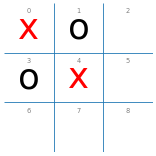


Win or draw:
Number of nodes searched: 22


[2,
 [['if', ['x', 'o', 'x', 'o', 'x', 'o', ' ', ' ', ' '], 'then', [6, 'win']],
  ['if',
   ['x', 'o', 'x', 'o', 'x', ' ', 'o', ' ', ' '],
   'then',
   [5,
    [['if', ['x', 'o', 'x', 'o', 'x', 'x', 'o', 'o', ' '], 'then', [8, 'win']],
     ['if',
      ['x', 'o', 'x', 'o', 'x', 'x', 'o', ' ', 'o'],
      'then',
      [7, 'draw']]]]],
  ['if',
   ['x', 'o', 'x', 'o', 'x', ' ', ' ', 'o', ' '],
   'then',
   [5,
    [['if', ['x', 'o', 'x', 'o', 'x', 'x', 'o', 'o', ' '], 'then', [8, 'win']],
     ['if',
      ['x', 'o', 'x', 'o', 'x', 'x', ' ', 'o', 'o'],
      'then',
      [6, 'win']]]]],
  ['if',
   ['x', 'o', 'x', 'o', 'x', ' ', ' ', ' ', 'o'],
   'then',
   [5,
    [['if',
      ['x', 'o', 'x', 'o', 'x', 'x', 'o', ' ', 'o'],
      'then',
      [7, 'draw']],
     ['if',
      ['x', 'o', 'x', 'o', 'x', 'x', ' ', 'o', 'o'],
      'then',
      [6, 'win']]]]]]]

CPU times: total: 0 ns
Wall time: 11.5 ms


In [6]:
board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[3] = 'o'
board[4] = 'x'

print("Board:")
show_board(board)

print()
print("Win or draw:")
%time display(and_or_search(board, player = 'x', draw_is_win = True))

Why does it play 2 and not 8!!!

In [7]:
print("Win only:")
%time display(and_or_search(board, player = 'x', draw_is_win = False))

Win only:
Number of nodes searched: 30


[2,
 [['if', ['x', 'o', 'x', 'o', 'x', 'o', ' ', ' ', ' '], 'then', [6, 'win']],
  ['if', ['x', 'o', 'x', 'o', 'x', ' ', 'o', ' ', ' '], 'then', [8, 'win']],
  ['if',
   ['x', 'o', 'x', 'o', 'x', ' ', ' ', 'o', ' '],
   'then',
   [5,
    [['if', ['x', 'o', 'x', 'o', 'x', 'x', 'o', 'o', ' '], 'then', [8, 'win']],
     ['if',
      ['x', 'o', 'x', 'o', 'x', 'x', ' ', 'o', 'o'],
      'then',
      [6, 'win']]]]],
  ['if', ['x', 'o', 'x', 'o', 'x', ' ', ' ', ' ', 'o'], 'then', [6, 'win']]]]

CPU times: total: 31.2 ms
Wall time: 6.57 ms


## x can draw_is_win if it chooses 7

Board:


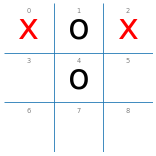


Win or draw:
Number of nodes searched: 64


[7,
 [['if',
   ['x', 'o', 'x', 'o', 'o', ' ', ' ', 'x', ' '],
   'then',
   [5,
    [['if', ['x', 'o', 'x', 'o', 'o', 'x', 'o', 'x', ' '], 'then', [8, 'win']],
     ['if',
      ['x', 'o', 'x', 'o', 'o', 'x', ' ', 'x', 'o'],
      'then',
      [6, 'draw']]]]],
  ['if',
   ['x', 'o', 'x', ' ', 'o', 'o', ' ', 'x', ' '],
   'then',
   [3,
    [['if',
      ['x', 'o', 'x', 'x', 'o', 'o', 'o', 'x', ' '],
      'then',
      [8, 'draw']],
     ['if',
      ['x', 'o', 'x', 'x', 'o', 'o', ' ', 'x', 'o'],
      'then',
      [6, 'win']]]]],
  ['if',
   ['x', 'o', 'x', ' ', 'o', ' ', 'o', 'x', ' '],
   'then',
   [3,
    [['if',
      ['x', 'o', 'x', 'x', 'o', 'o', 'o', 'x', ' '],
      'then',
      [8, 'draw']],
     ['if',
      ['x', 'o', 'x', 'x', 'o', ' ', 'o', 'x', 'o'],
      'then',
      [5, 'draw']]]]],
  ['if',
   ['x', 'o', 'x', ' ', 'o', ' ', ' ', 'x', 'o'],
   'then',
   [3,
    [['if', ['x', 'o', 'x', 'x', 'o', 'o', ' ', 'x', 'o'], 'then', [6, 'win']],
     ['if',
      ['x', '

CPU times: total: 15.6 ms
Wall time: 14.7 ms


In [8]:

board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[2] = 'x'
#board[3] = 'o'
board[4] = 'o'

print("Board:")
show_board(board)

print()
print("Win or draw:")
%time display(and_or_search(board, player = 'x', draw_is_win = True))

In [9]:
print("Win only:")
%time display(and_or_search(board, player = 'x', draw_is_win = False))

Win only:
Number of nodes searched: 69


None

CPU times: total: 15.6 ms
Wall time: 7.39 ms


## a bad situation

Board:


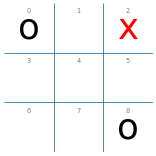


Win or draw:
Number of nodes searched: 155


None

CPU times: total: 0 ns
Wall time: 16.6 ms


In [10]:
board = empty_board() 
board[0] = 'o'
board[2] = 'x'
board[8] = 'o'

print("Board:")
show_board(board)

print()
print("Win or draw:")
%time display(and_or_search(board, player = 'x', draw_is_win = True))

## Empty board: Only a draw_is_win can be guaranteed

Board:


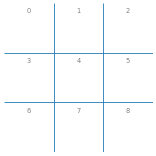


Win or draw:
Number of nodes searched: 966


[0,
 [['if',
   ['x', 'o', ' ', ' ', ' ', ' ', ' ', ' ', ' '],
   'then',
   [2,
    [['if',
      ['x', 'o', 'x', 'o', ' ', ' ', ' ', ' ', ' '],
      'then',
      [4,
       [['if',
         ['x', 'o', 'x', 'o', 'x', 'o', ' ', ' ', ' '],
         'then',
         [6, 'win']],
        ['if',
         ['x', 'o', 'x', 'o', 'x', ' ', 'o', ' ', ' '],
         'then',
         [5,
          [['if',
            ['x', 'o', 'x', 'o', 'x', 'x', 'o', 'o', ' '],
            'then',
            [8, 'win']],
           ['if',
            ['x', 'o', 'x', 'o', 'x', 'x', 'o', ' ', 'o'],
            'then',
            [7, 'draw']]]]],
        ['if',
         ['x', 'o', 'x', 'o', 'x', ' ', ' ', 'o', ' '],
         'then',
         [5,
          [['if',
            ['x', 'o', 'x', 'o', 'x', 'x', 'o', 'o', ' '],
            'then',
            [8, 'win']],
           ['if',
            ['x', 'o', 'x', 'o', 'x', 'x', ' ', 'o', 'o'],
            'then',
            [6, 'win']]]]],
        ['if',
        

CPU times: total: 46.9 ms
Wall time: 148 ms


In [11]:
board = empty_board() 

print("Board:")
show_board(board)

print()
print("Win or draw:")
%time display(and_or_search(board, player = 'x', draw_is_win = True))

In [12]:
print("Win only:")
%time display(and_or_search(board, player = 'x', draw_is_win = False))

Win only:
Number of nodes searched: 16213


None

CPU times: total: 453 ms
Wall time: 1.02 s


---
# Tổng hợp kết quả bốn trường hợp kiểm thử

Bốn bàn cờ kiểm thử (X đi tiếp): **(1)** X sắp thắng, **(2)** X cần tìm đường hòa, **(3)** tình huống bất lợi, **(4)** bàn cờ rỗng. Mỗi bàn được chạy với hai định nghĩa mục tiêu: *thắng hoặc hòa* (`draw_is_win=True`) và *chỉ thắng* (`draw_is_win=False`).

In [13]:
CASES = {}
b = empty_board(); b[0], b[1], b[3], b[4] = 'x', 'o', 'o', 'x'
CASES["(1) X sắp thắng"] = b
b = empty_board(); b[0], b[1], b[2], b[4] = 'x', 'o', 'x', 'o'
CASES["(2) X cần tìm đường hòa"] = b
b = empty_board(); b[0], b[2], b[8] = 'o', 'x', 'o'
CASES["(3) Tình huống bất lợi"] = b
CASES["(4) Bàn cờ rỗng"] = empty_board()

ROWS = []
for name, board in CASES.items():
    run_case(board, name, ROWS)
print_table(ROWS)

Trường hợp                  Mục tiêu   Nước đi            Số nút  Thời gian (ms)  Lá win  Lá draw  Độ sâu
---------------------------------------------------------------------------------------------------------
(1) X sắp thắng             thắng/hòa  2                      22            1.79       5        2       3
(1) X sắp thắng             chỉ thắng  2                      30            3.81       5        0       3
(2) X cần tìm đường hòa     thắng/hòa  7                      64            6.56       3        5       3
(2) X cần tìm đường hòa     chỉ thắng  không có kế hoạch      69            4.26       -        -       -
(3) Tình huống bất lợi      thắng/hòa  không có kế hoạch     155            7.25       -        -       -
(3) Tình huống bất lợi      chỉ thắng  không có kế hoạch     147            7.76       -        -       -
(4) Bàn cờ rỗng             thắng/hòa  0                     966           42.88      98       26       5
(4) Bàn cờ rỗng             chỉ thắng  không c

### Kế hoạch điều kiện của từng trường hợp (mục tiêu *thắng hoặc hòa*)

Hàm `print_plan` in kế hoạch dạng cây: mỗi nút *OR* là nước đi của X, mỗi nhánh *AND* là một phản ứng có thể có của O.

(1) X sắp thắng


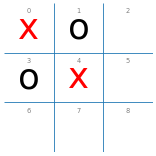


X đánh ô 2
  nếu O đánh ô 5:
        X đánh ô 6  =>  WIN
  nếu O đánh ô 6:
        X đánh ô 5
          nếu O đánh ô 7:
                X đánh ô 8  =>  WIN
          nếu O đánh ô 8:
                X đánh ô 7  =>  DRAW
  nếu O đánh ô 7:
        X đánh ô 5
          nếu O đánh ô 6:
                X đánh ô 8  =>  WIN
          nếu O đánh ô 8:
                X đánh ô 6  =>  WIN
  nếu O đánh ô 8:
        X đánh ô 5
          nếu O đánh ô 6:
                X đánh ô 7  =>  DRAW
          nếu O đánh ô 7:
                X đánh ô 6  =>  WIN

(2) X cần tìm đường hòa


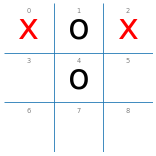


X đánh ô 7
  nếu O đánh ô 3:
        X đánh ô 5
          nếu O đánh ô 6:
                X đánh ô 8  =>  WIN
          nếu O đánh ô 8:
                X đánh ô 6  =>  DRAW
  nếu O đánh ô 5:
        X đánh ô 3
          nếu O đánh ô 6:
                X đánh ô 8  =>  DRAW
          nếu O đánh ô 8:
                X đánh ô 6  =>  WIN
  nếu O đánh ô 6:
        X đánh ô 3
          nếu O đánh ô 5:
                X đánh ô 8  =>  DRAW
          nếu O đánh ô 8:
                X đánh ô 5  =>  DRAW
  nếu O đánh ô 8:
        X đánh ô 3
          nếu O đánh ô 5:
                X đánh ô 6  =>  WIN
          nếu O đánh ô 6:
                X đánh ô 5  =>  DRAW

(3) Tình huống bất lợi


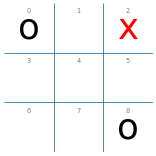


=> Không tồn tại kế hoạch đảm bảo thắng/hòa: and_or_search trả về None

(4) Bàn cờ rỗng


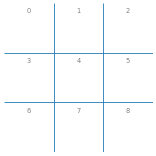


X đánh ô 0
  nếu O đánh ô 1:
        X đánh ô 2
            ... (còn 6 nhánh phản ứng của O chưa in)
  nếu O đánh ô 2:
        X đánh ô 3
            ... (còn 6 nhánh phản ứng của O chưa in)
  nếu O đánh ô 3:
        X đánh ô 1
            ... (còn 6 nhánh phản ứng của O chưa in)
  nếu O đánh ô 4:
        X đánh ô 1
            ... (còn 6 nhánh phản ứng của O chưa in)
  nếu O đánh ô 5:
        X đánh ô 2
            ... (còn 6 nhánh phản ứng của O chưa in)
  nếu O đánh ô 6:
        X đánh ô 1
            ... (còn 6 nhánh phản ứng của O chưa in)
  nếu O đánh ô 7:
        X đánh ô 1
            ... (còn 6 nhánh phản ứng của O chưa in)
  nếu O đánh ô 8:
        X đánh ô 2
            ... (còn 6 nhánh phản ứng của O chưa in)



In [14]:
DEBUG = 0
for name, board in CASES.items():
    print("=" * 70); print(name); show_board(board); print()
    plan = and_or_search(board, 'x', True)
    if plan is None:
        print("=> Không tồn tại kế hoạch đảm bảo thắng/hòa: and_or_search trả về None")
    else:
        print_plan(plan, board, max_depth=2 if name.startswith("(4)") else 3)
    print()
DEBUG = 1

## Experiments

### And-Or Tree Search vs. Random

Put AND-OR search into a wrapper agent function. Note that if AND-OR search cannot guarantee a win then
it does not return a plan, nut `None`. In this case, we do not know what the best (i.e., the least "bad") 
move is, so I make the agent play randomly. Other methods that we will learn about later can determine the utility of a move, even if it does not guarantee a win.

In [15]:
DEBUG = 0

def and_or_player(board, player = 'x'):
    plan = and_or_search(board, player)

    # if there is no plan then we do a random action
    if plan is None: 
        return np.random.choice(actions(board))
    else:
        return plan[0]


print("and-or-search vs. random:")
%time display(play(and_or_player, random_player))

print()
print("random vs. and-or-search")
%time display(play(random_player, and_or_player))

and-or-search vs. random:


{'x': 98, 'o': 0, 'd': 2}

CPU times: total: 2.94 s
Wall time: 9.92 s

random vs. and-or-search


{'x': 0, 'o': 71, 'd': 29}

CPU times: total: 2.47 s
Wall time: 7.3 s


### `and_or_player` đấu `random_player` (100 ván mỗi chiều)

Đo thêm thời gian trung bình cho mỗi nước đi của tác tử (`and_or_player` tạo lại kế hoạch ở mỗi lượt).

In [16]:
def timed(agent):
    """Bọc một tác tử để đo tổng thời gian và số lần được gọi."""
    stats = {"t": 0.0, "n": 0}
    def f(board, player='x'):
        t0 = time.perf_counter()
        a = agent(board, player)
        stats["t"] += time.perf_counter() - t0
        stats["n"] += 1
        return a
    return f, stats

DEBUG = 0
np.random.seed(2024)
N = 100
ao, ao_stats = timed(and_or_player)

res_x = play(ao, random_player, N=N)        # AND-OR đi trước (X)
t_x, n_x = ao_stats["t"], ao_stats["n"]
ao_stats["t"], ao_stats["n"] = 0.0, 0
res_o = play(random_player, ao, N=N)        # AND-OR đi sau (O)
t_o, n_o = ao_stats["t"], ao_stats["n"]

print(f"{'Vai trò của AND-OR':<22}{'Số ván':>7}{'AND-OR thắng':>14}{'Hòa':>6}{'AND-OR thua':>13}{'TB ms/nước':>12}")
print(f"{'X (đi trước)':<22}{N:>7}{res_x['x']:>14}{res_x['d']:>6}{res_x['o']:>13}{1000*t_x/n_x:>12.2f}")
print(f"{'O (đi sau)':<22}{N:>7}{res_o['o']:>14}{res_o['d']:>6}{res_o['x']:>13}{1000*t_o/n_o:>12.2f}")

Vai trò của AND-OR     Số ván  AND-OR thắng   Hòa  AND-OR thua  TB ms/nước
X (đi trước)              100            98     2            0       16.19
O (đi sau)                100            71    29            0       20.00


### Nhận xét – `and_or_player` đấu `random_player` (100 ván mỗi chiều)

* Khi **đi trước (X)**: 98 thắng – 2 hòa – 0 thua. Khi **đi sau (O)**: 71 thắng – 29 hòa – 0 thua. AND-OR **không thua ván nào** vì mục tiêu của nó là *thắng hoặc hòa* và tìm được kế hoạch đảm bảo điều đó ở hầu hết các lượt.
* Đi sau thì ít thắng hơn vì không có lợi thế nước đi đầu: O chỉ thắng khi X ngẫu nhiên đánh sai, còn X (đi trước) có chiến lược tạo ra hai đe dọa cùng lúc nên hầu như thắng chắc.
* Thời gian trung bình khoảng 1 ms mỗi nước đi. Tác tử là *simple reflex agent* nên mỗi lượt tạo lại kế hoạch điều kiện từ đầu (như ghi chú của notebook); có thể tăng tốc bằng cách lưu sẵn kế hoạch của bàn rỗng và chỉ tra cứu.

**Note how slow this is!**

My lazy implementation is a _simple reflex agent_ that recreates a conditional plan every time it is asked for an action. ut since And-Or search already produces a complete conditional plan for the empty board, a better implementation would use a _model-based reflex agent_ that store this precomputed plan and just follow it without more planing.

### And-Or Tree Search vs. And-Or Tree Search

In [17]:
# No randomness -> run only once

%time display(play(and_or_player, and_or_player, N = 1))

{'x': 0, 'o': 0, 'd': 1}

CPU times: total: 31.2 ms
Wall time: 86.2 ms
